## Setup

In [ ]:
# If you are using the docker image it should work out of the box. No additional setup is needed.

# If you are doing a local installation:
## You need to compile the modified GrabCut algorithm before you can call the automatic segmentation functions below.
## - Install OpenCV
## - Compile modified GrabCut using /Notebook/CppSource/DisplayMat/Makefile
## You also need to install the pydicom package to read/write dicoms. 

## Import Functions

In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

In [2]:
from Source.autoSegment import autoSegmentFromDicom
from Source.ipythonWidgets import overlayViewer, reconViewer

## Automatic Segmentation

In [48]:
# You need to specify your own input path here.
#input_directory = '/data/Gris 1/Projekt_534_Projekt_534/Unnamed - 2674/3D_Ax_DISCO_Star_28/'
#input_directory = '/data/Gris 2/Projekt_534_Projekt_534/Unnamed - 2679/3D_Ax_DISCO_Star_28/'
#input_directory = '/data/Gris 3/Projekt_534_Projekt_534/Unnamed - 2714/3D_Ax_DISCO_Star_41/'
input_directory = '/data/Gris 4/Projekt_534_Peojekt_534/Unnamed - 2719/3D_Ax_DISCO_Star_35/'

## Automatic Segmentation (no classification)

In [54]:
# =========================================================
# PIPELINE: MoCo + PCA renal segmentation (healthy kidneys)
# Cortex  = largest cluster
# Medulla = strongest late accumulation among remaining
# Pelvis  = remaining (+ optional indent/hilum swap)
# =========================================================

import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from ipywidgets import IntSlider, ToggleButton, interactive_output, VBox, Layout
from IPython.display import display
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from skimage.morphology import convex_hull_image
from scipy.ndimage import (
    binary_fill_holes,
    binary_erosion,
    binary_dilation,
    distance_transform_edt,
    label as cc_label,
    uniform_filter,
    affine_transform,
    center_of_mass,
)
from scipy.optimize import minimize

from Source.util import dicom2hdf5
from Source.segmentation import renal_segment_v4
from Source.dicom_load_tolerant import load_dicom_dataset


# -------------------------------------------------
# 1. Load data
# -------------------------------------------------
# input_directory = r'/data/your/path/'

dataset = load_dicom_dataset(input_directory, quarantine=True, always_scan=True)
recon      = dataset['recon']
temp_res   = dataset['temp_res'] / 1000.0   # if TriggerTime is in ms
spacing    = np.array(dataset['spacing'], dtype=float)
dicom_list = dataset['dicom_list']

print('Original shape:', recon.shape)
print('spacing (mm):', spacing)
print('temp_res (s):', temp_res)

# -------------------------------------------------
# 2. Drop mis-sorted last frame
# -------------------------------------------------
recon = recon[..., :-1]
print('After drop last frame:', recon.shape)

# -------------------------------------------------
# 3. First GrabCut
# -------------------------------------------------
source_path = os.path.dirname(os.path.realpath('/renal-segmentation/Source/segmentation.py'))
root_path   = os.path.abspath(os.path.join(source_path, '..'))

print('Running first GrabCut...')
gc_labels = renal_segment_v4(
    recon, temp_res=temp_res, spacing=spacing,
    root_path=root_path, threshold_multiplier=1,
)
print('GrabCut labels:', np.unique(gc_labels))



# -------------------------------------------------
# 6. PCA map
# -------------------------------------------------
print('Computing PCA...')
recon_diff = recon - np.amin(recon, axis=3, keepdims=True)
sig = recon_diff.reshape(-1, recon.shape[-1]).astype(np.float32)
pca = PCA(n_components=3)
coeffs = pca.fit_transform(sig)
pca_map = coeffs.reshape(recon.shape[:3] + (3,))
for ch in range(3):
    c = pca_map[..., ch]
    c -= c.min()
    c /= (c.max() + 1e-8)
    pca_map[..., ch] = c
print('PCA done.')

# -------------------------------------------------
# 7. Hole-fill GrabCut
# -------------------------------------------------
kidney_raw = gc_labels > 0
kidney_filled = np.zeros_like(kidney_raw)
for z in range(kidney_raw.shape[2]):
    kidney_filled[:, :, z] = binary_fill_holes(kidney_raw[:, :, z])

idx = distance_transform_edt(~kidney_raw, return_distances=False, return_indices=True)
gc_filled = gc_labels[idx[0], idx[1], idx[2]]
gc_filled[~kidney_filled] = 0
kidney = gc_filled > 0

# -------------------------------------------------
# 8. K-means (3 clusters)
# -------------------------------------------------
pts = pca_map[kidney]
kmeans = KMeans(n_clusters=3, random_state=0, n_init=10)
cluster_id = kmeans.fit_predict(pts)
cluster_vol = np.zeros(recon.shape[:3], dtype=np.int8)
cluster_vol[kidney] = cluster_id + 1

# -------------------------------------------------
# 9. Cluster → tissue (NEW RULES)
#     Cortex  = largest cluster
#     Medulla = best late-accumulation among other two
#     Pelvis  = remaining; optional indent/hilum swap
# -------------------------------------------------
time = np.arange(recon.shape[3]) * temp_res
nt = recon.shape[3]
i_early_end = max(2, int(round(40.0 / temp_res)))
i_late0 = int(0.80 * nt)

sizes = {}
curves = {}
late_mean = {}
last_minus_early = {}
early_sharp = {}

for cid in (1, 2, 3):
    m = cluster_vol == cid
    sizes[cid] = int(m.sum())
    if sizes[cid] == 0:
        curves[cid] = None
        late_mean[cid] = -np.inf
        last_minus_early[cid] = -np.inf
        early_sharp[cid] = 0.0
        continue
    curve = recon[m].mean(axis=0)
    curves[cid] = curve
    late_mean[cid] = float(curve[i_late0:].mean())
    # early peak window
    early = curve[:i_early_end]
    i_pk = int(np.argmax(early))
    s_pk = float(early[i_pk])
    s_base = float(curve[:max(1, i_pk)].mean()) if i_pk > 0 else float(curve[0])
    s_last = float(curve[-1])
    last_minus_early[cid] = s_last - s_pk
    # sharpness: early rise relative to total dynamic range
    dyn = float(curve.max() - curve.min()) + 1e-8
    early_sharp[cid] = max(0.0, (s_pk - s_base) / dyn)
    print('Cluster %d: n=%d  late=%.1f  last-early=%.1f  sharp=%.3f' % (
        cid, sizes[cid], late_mean[cid], last_minus_early[cid], early_sharp[cid]))

# 9a. Cortex = largest
cortex_id = max(sizes, key=sizes.get)
print('Cortex (largest) = cluster %d (%d vox)' % (cortex_id, sizes[cortex_id]))

# 9b. Medulla vs pelvis among remaining
remaining = [c for c in (1, 2, 3) if c != cortex_id]

def accumulation_score(cid):
    # high late, high last-early, low early sharpness
    return (
        late_mean[cid]
        + last_minus_early[cid]
        - 0.5 * early_sharp[cid] * (abs(late_mean[cid]) + 1.0)
    )

scores = {c: accumulation_score(c) for c in remaining}
print('Accumulation scores:', scores)
medulla_id = max(scores, key=scores.get)
pelvis_id = [c for c in remaining if c != medulla_id][0]
print('Before indent check: medulla=%d pelvis=%d' % (medulla_id, pelvis_id))

# 9c. Build indent (largest per kidney) for hilum contact check
gc_original = gc_filled > 0
gc_temp_id = np.zeros_like(gc_filled)
for kid_id in kid_ids:
    m = gc_filled == kid_id
    hull = np.zeros_like(m)
    for z in range(m.shape[2]):
        sl = m[:, :, z]
        if sl.sum() >= 20:
            hull[:, :, z] = convex_hull_image(sl)
    all_indents = hull & ~m
    labeled, n = cc_label(all_indents)
    if n == 0:
        temp_k = m.copy()
    else:
        sz = np.bincount(labeled.ravel())
        sz[0] = 0
        main_indent = labeled == sz.argmax()
        temp_k = m | main_indent
    gc_temp_id[temp_k & (gc_temp_id == 0)] = kid_id

gc_temp = gc_temp_id > 0
indent = gc_temp & ~gc_original

# Indent contact fraction for non-cortex clusters
def indent_fraction(cid):
    m = cluster_vol == cid
    if m.sum() == 0:
        return 0.0
    return float((m & indent).sum()) / float(m.sum())

f_med = indent_fraction(medulla_id)
f_pel = indent_fraction(pelvis_id)
print('Indent fraction: medulla=%.3f pelvis=%.3f' % (f_med, f_pel))

# Swap if scores are close and indent contact clearly disagrees
score_gap = abs(scores[medulla_id] - scores[pelvis_id])
score_scale = abs(scores[medulla_id]) + abs(scores[pelvis_id]) + 1e-6
if (f_med > f_pel + 0.02) and (score_gap / score_scale < 0.25):
    medulla_id, pelvis_id = pelvis_id, medulla_id
    print('Indent swap → medulla=%d pelvis=%d' % (medulla_id, pelvis_id))

print('Assignment → cortex=%d  medulla=%d  pelvis=%d' % (cortex_id, medulla_id, pelvis_id))

# 9d. Voxel-wise medulla tighten
late_vol = recon[..., i_late0:].mean(axis=3)
# early peak proxy volume
early_peak = recon[..., :i_early_end].max(axis=3)
baseline = recon[..., :max(1, int(round(5.0 / temp_res)))].mean(axis=3)
early_enh = early_peak - baseline
rise_map = recon[..., -1] - early_peak  # last - early peak

med_cluster = cluster_vol == medulla_id
n_med_before = int(med_cluster.sum())
if n_med_before > 0:
    RISE_PERCENTILE = 40
    rise_thr = np.percentile(rise_map[med_cluster], RISE_PERCENTILE)
    ctx_cluster = cluster_vol == cortex_id
    early_thr = np.median(early_enh[ctx_cluster]) if np.any(ctx_cluster) else np.median(early_enh[kidney])
    med_tight = med_cluster & (rise_map >= rise_thr) & (early_enh < early_thr)
    med_dropped = med_cluster & ~med_tight
    print('Medulla tighten: %d → %d' % (n_med_before, int(med_tight.sum())))
else:
    med_tight = med_cluster
    med_dropped = np.zeros_like(med_cluster)

cluster_vol_refined = cluster_vol.copy()
cluster_vol_refined[med_dropped] = 0

# -------------------------------------------------
# 10. Geometry-aware labels
# -------------------------------------------------
final_labels = np.zeros(recon.shape[:3], dtype=np.uint8)
voxel_vol_mm3 = float(np.prod(spacing))

# 10a. PCA labels
for kid_id in kid_ids:
    mask = gc_filled == kid_id
    if kid_id == 1:
        final_labels[mask & (cluster_vol_refined == cortex_id)] = 2
        final_labels[mask & med_tight] = 4
        final_labels[mask & (cluster_vol_refined == pelvis_id)] = 6
    else:
        final_labels[mask & (cluster_vol_refined == cortex_id)] = 3
        final_labels[mask & med_tight] = 5
        final_labels[mask & (cluster_vol_refined == pelvis_id)] = 7

final_labels[med_dropped & gc_original & (final_labels == 0)] = 1

# 10b. Temp / indent already computed; print sizes
print('Total indent voxels:', int(indent.sum()))

# 10c. Brim crop = fraction of equivalent radius
RADIUS_FRACTION = 0.15
CROP_MM_MIN, CROP_MM_MAX = 3.0, 8.0
mean_spacing = float(np.mean(spacing))
gc_temp_cropped = np.zeros_like(gc_temp)

for kid_id in kid_ids:
    m_temp = gc_temp_id == kid_id
    n_vox = int(m_temp.sum())
    if n_vox == 0:
        continue
    vol_mm3 = n_vox * voxel_vol_mm3
    radius_mm = (3.0 * vol_mm3 / (4.0 * np.pi)) ** (1.0 / 3.0)
    crop_mm = float(np.clip(RADIUS_FRACTION * radius_mm, CROP_MM_MIN, CROP_MM_MAX))
    crop_vox = max(1, int(round(crop_mm / mean_spacing)))
    print('Kidney %d: R=%.1f mm crop=%.1f mm (%d vox)' % (kid_id, radius_mm, crop_mm, crop_vox))
    m = m_temp.copy()
    for _ in range(crop_vox):
        m = binary_erosion(m)
    gc_temp_cropped |= m

# 10d. Brim → cortex (outer shell always cortex)
brim = gc_original & ~gc_temp_cropped
for kid_id in kid_ids:
    m = brim & (gc_filled == kid_id)
    final_labels[m] = 2 if kid_id == 1 else 3
final_labels[brim & ((final_labels == 6) | (final_labels == 7))] = 0
for kid_id in kid_ids:
    m = brim & (gc_filled == kid_id) & ((final_labels == 0) | (final_labels == 1))
    final_labels[m] = 2 if kid_id == 1 else 3

# 10e. Leftover → uncertain
final_labels[gc_original & (final_labels == 0)] = 1

# 10f. Indent → pelvis
final_labels[indent] = 0
for kid_id in kid_ids:
    m = indent & (gc_temp_id == kid_id)
    final_labels[m] = 6 if kid_id == 1 else 7
still = indent & ((final_labels == 0) | (final_labels == 1))
if np.any(still):
    idx = distance_transform_edt(~gc_original, return_distances=False, return_indices=True)
    nearest = gc_filled[idx[0], idx[1], idx[2]]
    for kid_id in kid_ids:
        final_labels[still & (nearest == kid_id)] = 6 if kid_id == 1 else 7

# 10g. Connectivity: cortex largest→stray medulla; pelvis largest→stray cortex
for kid_id in kid_ids:
    ctx_val = 2 if kid_id == 1 else 3
    med_val = 4 if kid_id == 1 else 5
    pel_val = 6 if kid_id == 1 else 7
    m = final_labels == ctx_val
    if np.any(m):
        labeled, n = cc_label(m)
        if n > 1:
            sz = np.bincount(labeled.ravel()); sz[0] = 0
            keep = labeled == sz.argmax()
            final_labels[m & ~keep] = med_val
    m = final_labels == pel_val
    if np.any(m):
        labeled, n = cc_label(m)
        if n > 1:
            sz = np.bincount(labeled.ravel()); sz[0] = 0
            keep = labeled == sz.argmax()
            final_labels[m & ~keep] = ctx_val

# 10h. Cortex mostly surrounded by pelvis → uncertain
PELVIS_SURROUND_THR = 0.45
pelvis_mask = (final_labels == 6) | (final_labels == 7)
cortex_mask = (final_labels == 2) | (final_labels == 3)
pelvis_frac = uniform_filter(pelvis_mask.astype(np.float32), size=3)
cortex_in_pelvis = cortex_mask & (pelvis_frac >= PELVIS_SURROUND_THR)
final_labels[cortex_in_pelvis] = 1
print('Cortex→uncertain (pelvis surround):', int(cortex_in_pelvis.sum()))

uncertain_mask = final_labels == 1
print('Uncertain (before drop):', int(uncertain_mask.sum()))
final_labels[uncertain_mask] = 0

print('Final labels:', np.unique(final_labels))
print('Cortex :', int(np.sum((final_labels == 2) | (final_labels == 3))))
print('Medulla:', int(np.sum((final_labels == 4) | (final_labels == 5))))
print('Pelvis :', int(np.sum((final_labels == 6) | (final_labels == 7))))

# -------------------------------------------------
# 11. Viewer
# -------------------------------------------------
def overlay_bool(ax, img, mask, cmap, alpha=0.5):
    ax.imshow(img, cmap='gray', interpolation='none')
    if mask is not None and np.any(mask):
        ov = mask.astype(float).copy()
        ov[ov == 0] = np.nan
        ax.imshow(ov, cmap=cmap, alpha=alpha, vmin=0.5, vmax=1.5, interpolation='none')
    ax.axis('off')

LEGEND_ITEMS = [
    (2, 'L Cortex'), (3, 'R Cortex'),
    (4, 'L Medulla'), (5, 'R Medulla'),
    (6, 'L Pelvis'), (7, 'R Pelvis'),
]

def make_label_patches():
    cmap = plt.cm.jet
    norm = plt.Normalize(vmin=2, vmax=7)
    handles, labels = [], []
    for val, name in LEGEND_ITEMS:
        handles.append(mpatches.Patch(color=cmap(norm(val))))
        labels.append('%d: %s' % (val, name))
    return handles, labels

slider_layout = Layout(width='280px')
xx_slider = IntSlider(
    value=recon.shape[0] // 2, min=0, max=recon.shape[0] - 1, step=1,
    description='xx', continuous_update=True, layout=slider_layout)
tt_slider = IntSlider(
    value=0, min=0, max=recon.shape[3] - 1, step=1,
    description='tt', continuous_update=True, layout=slider_layout)
show_seg_btn = ToggleButton(value=True, description='Show final labels')

def show_all(xx, tt, show_seg):
    img = np.rot90(recon[xx, :, :, tt], k=1)
    lab = np.rot90(final_labels[xx, :, :], k=1)
    pca_s = np.rot90(pca_map[xx], k=1)
    orig_s = np.rot90(gc_original[xx], k=1)
    temp_s = np.rot90(gc_temp[xx], k=1)
    crop_s = np.rot90(gc_temp_cropped[xx], k=1)
    brim_s = np.rot90(brim[xx], k=1)
    indent_s = np.rot90(indent[xx], k=1)
    unc_s = np.rot90(uncertain_mask[xx], k=1)

    fig, axes = plt.subplots(
        3, 4, figsize=(9.0, 7.0), dpi=100,
        gridspec_kw={'width_ratios': [1, 1, 1, 0.45]})
    for r in range(3):
        axes[r, 3].axis('off')
    ax_leg = axes[1, 3]

    axes[0, 0].imshow(img, cmap='gray', interpolation='none')
    axes[0, 0].set_title('Anatomy (MoCo)', fontsize=9)
    axes[0, 0].axis('off')

    axes[0, 1].imshow(pca_s, interpolation='none')
    axes[0, 1].set_title('PCA map', fontsize=9)
    axes[0, 1].axis('off')

    axes[0, 2].imshow(img, cmap='gray', interpolation='none')
    if show_seg and np.any(lab > 0):
        ov = lab.astype(float).copy()
        ov[ov == 0] = np.nan
        axes[0, 2].imshow(ov, cmap='jet', alpha=0.5, vmin=2, vmax=7, interpolation='none')
    axes[0, 2].set_title('Final labels', fontsize=9)
    axes[0, 2].axis('off')

    overlay_bool(axes[1, 0], img, orig_s, 'Blues')
    axes[1, 0].set_title('Original GrabCut', fontsize=9)
    overlay_bool(axes[1, 1], img, temp_s, 'Greens')
    axes[1, 1].set_title('Temp (indent filled)', fontsize=9)
    overlay_bool(axes[1, 2], img, crop_s, 'Oranges')
    axes[1, 2].set_title('Temp cropped', fontsize=9)

    overlay_bool(axes[2, 0], img, brim_s, 'Reds', alpha=0.6)
    axes[2, 0].set_title('Brim → cortex', fontsize=9)
    overlay_bool(axes[2, 1], img, unc_s, 'YlOrBr', alpha=0.65)
    axes[2, 1].set_title('Uncertain (excluded)', fontsize=9)

    axes[2, 2].imshow(img, cmap='gray', interpolation='none')
    for msk, cm, a in [(brim_s, 'Reds', 0.45), (indent_s, 'Purples', 0.45), (unc_s, 'YlOrBr', 0.5)]:
        if np.any(msk):
            ov = msk.astype(float).copy()
            ov[ov == 0] = np.nan
            axes[2, 2].imshow(ov, cmap=cm, alpha=a, vmin=0.5, vmax=1.5, interpolation='none')
    axes[2, 2].set_title('Brim+Indent+Uncertain', fontsize=9)
    axes[2, 2].axis('off')

    handles, labels = make_label_patches()
    ax_leg.legend(handles=handles, labels=labels, loc='center', fontsize=8,
                  framealpha=0.95, title='Final labels')
    fig.suptitle('xx=%d  tt=%d' % (xx, tt), fontsize=11)
    plt.tight_layout()
    plt.show()

out = interactive_output(
    show_all, {'xx': xx_slider, 'tt': tt_slider, 'show_seg': show_seg_btn})
display(VBox([xx_slider, tt_slider, show_seg_btn, out]))

Scanning 4880 files for unreadable DICOM...
	0/4880
	500/4880
	1000/4880
	1500/4880
	2000/4880
	2500/4880
	3000/4880
	3500/4880
	4000/4880
	4500/4880
Unreadable files: 33
Quarantined 33 files under /data/Gris 4/Projekt_534_Peojekt_534/Unnamed - 2719/3D_Ax_DISCO_Star_35/_bad_dicom
Trying standard dicom2hdf5...
4847 files found
	0/4847
	484/4847
	968/4847
	1452/4847
	1936/4847
	2420/4847
	2904/4847
	3388/4847
	3872/4847
	4356/4847
	4840/4847
	Done
Triggers(ms): [0, 2612, 5224, 7837, 10449, 13062, 15674, 18286, 20899, 23511, 26124, 28736, 31349, 33961, 36573, 39186, 41798, 44411, 47023, 49636, 52248, 54860, 57473, 60085, 62698, 65310, 67923, 70535, 73147, 75760, 78372, 80985, 83597, 86210, 88822, 91434, 94047, 96659, 99272, 101884, 104497, 107109, 109721, 112334, 114946, 117559, 120171, 122784, 125396, 128008, 130621, 133233, 135846, 138458, 141071, 143683, 146295, 148908, 151520, 154133, 52380000, 52381000]
Standard loader failed: Data size is inconsistent!
Falling back to dicom2hdf5_tol

A Jupyter Widget

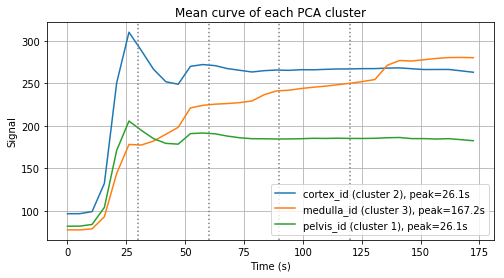

In [55]:
fig, ax = plt.subplots(figsize=(8, 4))
for cid, name in [(cortex_id, 'cortex_id'), (medulla_id, 'medulla_id'), (pelvis_id, 'pelvis_id')]:
    m = cluster_vol == cid
    if not np.any(m):
        continue
    curve = recon[m].mean(axis=0)
    ax.plot(time, curve, label='%s (cluster %d), peak=%.1fs' % (name, cid, time[np.argmax(curve)]))
ax.axvline(30, color='gray', ls=':')
ax.axvline(60, color='gray', ls=':')
ax.axvline(90, color='gray', ls=':')
ax.axvline(120, color='gray', ls=':')
ax.set_xlabel('Time (s)')
ax.set_ylabel('Signal')
ax.legend()
ax.set_title('Mean curve of each PCA cluster')
ax.grid(True)
plt.show()

A Jupyter Widget

A Jupyter Widget

A Jupyter Widget

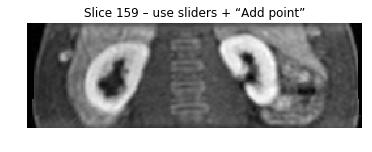

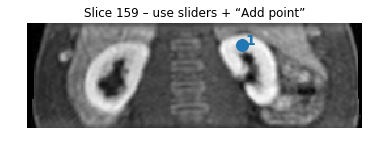

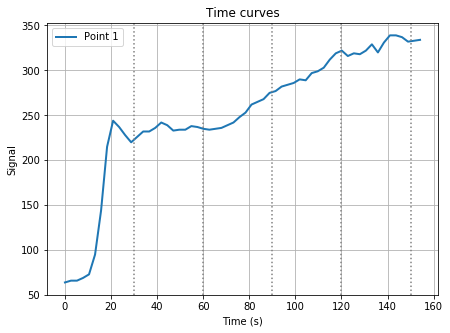

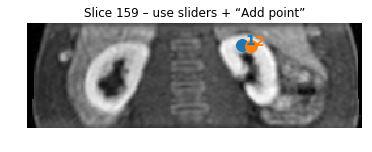

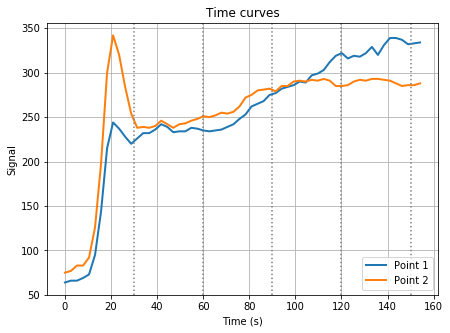

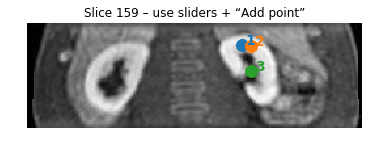

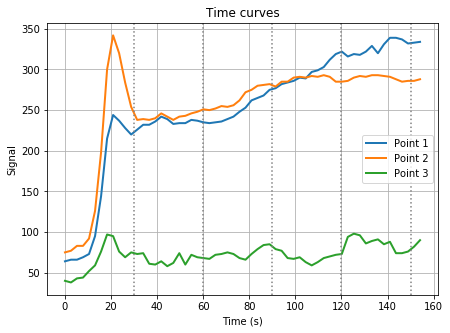

In [28]:
get_ipython().magic('matplotlib inline')
from ipywidgets import interact, IntSlider, Button, Output, HBox, VBox
import matplotlib.pyplot as plt
import numpy as np

xx = 159
tt_show = min(int(round(90 / temp_res)), recon.shape[3]-1)
img = np.rot90(recon[xx, :, :, tt_show], k=1)
ny, nz = img.shape          # after rotation

time = np.arange(recon.shape[3]) * temp_res

# storage
selected = []

out_img   = Output()
out_curve = Output()

def redraw():
    with out_img:
        out_img.clear_output(wait=True)
        fig, ax = plt.subplots(figsize=(6, 6))
        ax.imshow(img, cmap='gray', interpolation='none')
        colors = ['tab:blue', 'tab:orange', 'tab:green']
        for i, (r, c) in enumerate(selected):
            ax.plot(c, r, 'o', color=colors[i], markersize=12)
            ax.text(c+3, r, str(i+1), color=colors[i], fontsize=14, weight='bold')
        ax.set_title(f'Slice {xx} – use sliders + “Add point”')
        ax.axis('off')
        plt.show()

    with out_curve:
        out_curve.clear_output(wait=True)
        if not selected:
            return
        fig, ax = plt.subplots(figsize=(7, 5))
        colors = ['tab:blue', 'tab:orange', 'tab:green']
        for i, (r, c) in enumerate(selected):
            # convert rotated coordinates back to volume
            orig_y = c
            orig_z = ny - 1 - r
            curve = recon[xx, orig_y, orig_z, :]
            ax.plot(time, curve, color=colors[i], label=f'Point {i+1}', linewidth=2)
        for t_ in [30, 60, 90, 120, 150]:
            ax.axvline(t_, color='gray', linestyle=':')
        ax.set_xlabel('Time (s)')
        ax.set_ylabel('Signal')
        ax.legend()
        ax.grid(True)
        ax.set_title('Time curves')
        plt.show()

# sliders for cursor position
row_slider = IntSlider(value=ny//2, min=0, max=ny-1, description='row')
col_slider = IntSlider(value=nz//2, min=0, max=nz-1, description='col')

def add_point(b):
    if len(selected) >= 3:
        return
    selected.append((row_slider.value, col_slider.value))
    redraw()

def undo_point(b):
    if selected:
        selected.pop()
        redraw()

def clear_points(b):
    selected.clear()
    redraw()

btn_add   = Button(description='Add point', button_style='success')
btn_undo  = Button(description='Undo', button_style='warning')
btn_clear = Button(description='Clear', button_style='danger')

btn_add.on_click(add_point)
btn_undo.on_click(undo_point)
btn_clear.on_click(clear_points)

# live cross-hair preview
def update_preview(row, col):
    with out_img:
        out_img.clear_output(wait=True)
        fig, ax = plt.subplots(figsize=(6, 6))
        ax.imshow(img, cmap='gray', interpolation='none')
        # existing points
        colors = ['tab:blue', 'tab:orange', 'tab:green']
        for i, (r, c) in enumerate(selected):
            ax.plot(c, r, 'o', color=colors[i], markersize=12)
            ax.text(c+3, r, str(i+1), color=colors[i], fontsize=14, weight='bold')
        # current cursor
        ax.axhline(row, color='yellow', alpha=0.6)
        ax.axvline(col, color='yellow', alpha=0.6)
        ax.plot(col, row, 'y+', markersize=15)
        ax.set_title(f'Slice {xx}')
        ax.axis('off')
        plt.show()

# layout
controls = HBox([row_slider, col_slider, btn_add, btn_undo, btn_clear])
display(controls)
display(HBox([out_img, out_curve]))

# connect preview
interact(update_preview, row=row_slider, col=col_slider)
redraw()